# Gerador de cartas de Magic - Apresentação

Meu nome é Giordano Debenedetti, aluno do último semestre do curso de Tecnologia em Análise e Desenvolvimento de Sistemas no IFRS - Canoas. Esse aplicativo foi elaborado como trabalho final da disciplina de Tópicos Especiais em Computação, lecionada pelo professor Rafael Coimbra Pinto. O conteúdo principal ministrado na cadeira é a linguagem Python e as suas principais bibliotecas para ML/IA, entre elas, as utilizadas nesta aplicação: NLTK, Pandas, Numpy, Matplotlib, Scikit-Learn e LLMs.

A inspiração para este projeto foi um website lançado no auge da pandemia, o site gerava cartas de magic coesas e criativas apenas com um input de nome, sendo opcional informar a(s) cor(es) e tipo(s). O modelo utilizado e treinado na época foi o GPT-2 e foi uma febre dentro da comunidade de magic, com os principais criadores de conteúdo de magic utilizando, criando conteúdo sobre e disciminando o uso da ferramenta.

Seis anos depois eu procurei a site na internet e descobri que os servidores já não funcionam mais. Existem outros sites parecidos, além das LLMs mais famosas, como ChapGPT ou Claude, que servem para criar cartas de magic. Porém, por experiência pessoal, nenhuma consegue chegar em um nível de criatividade e coesão como aquele site lançado em 2020. Daí surge a minha inspiração, será que eu consigo fazer uma ferramenta que funcione tão bem quanto aquela?

## Projeto de implementação

Comecei então a pensar em possibilidades, sempre pensando nas ferramentas que foram estudadas em aula. Cheguei a pensar em usar LLM pura, com um chamada de API para criar o texto e outra para criar a arte, porém já existem pelo menos 4 ou 5 sites que oferecem o mesmo serviço (pago). Então comecei a olhar para as ferramentas e modelos de NLP que foram apresentados durante o curso e pensei que poderia começar utilizando o NLTK e cadeias de Markov treinadas em cima do texto das cartas de magic.



## Como a carta é montada

Foi por aí que comecei: com o NLTK e uma cadeia de Markov. Antes de entrar em cada modelo, vale ter a visão do todo. O gerador monta a carta em cinco etapas, e a ordem importa: cada etapa usa o resultado da anterior.

1. **Tipo** — o usuário escolhe, o sistema tenta inferir pelo nome ou sorteia (`src/pipeline/tipo_por_nome.py`).
2. **Subtipos** — "Human Warrior", "Equipment", "Forest Island"... sorteados com as probabilidades reais do corpus, condicionadas ao tipo e à cor (`src/pipeline/subtipos.py`).
3. **Texto de regras** — a cadeia de Markov treinada só com cartas daquele tipo e daquela cor (`src/pipeline/texto_markov.py`).
4. **Regras do tipo** — Aura sempre ganha "Enchant", Equipamento ganha "Equip", terreno básico ganha a habilidade de mana (`src/pipeline/regras_tipo.py`).
5. **Custo e P/T** — dois modelos de regressão leem o texto final e preveem o custo de mana; para criaturas, também o poder e a resistência (`src/pipeline/estrutura.py`).

O **M1** é esse pipeline inteiro. O **M2** é o M1 com o texto de regras reescrito por um LLM, mantendo tipo, custo, P/T e keywords. O **M3** é o LLM gerando a carta inteira — mas ainda recebe do pipeline o tipo já resolvido, para os três braços serem comparáveis.

> A ideia central é dividir para conquistar: em vez de um modelo gigante que cospe a carta inteira, vários modelos pequenos, cada um especializado em uma decisão.


## O texto: bigramas, trigramas e um pouco além

Minha ideia inicial era usar uma **cadeia de Markov**. A ideia é simples: olhar para o texto das cartas reais e contar qual palavra costuma vir depois de qual.

- **Bigrama** (olha 1 palavra atrás): depois de "draw a", provavelmente vem "card".
- **Trigrama** (olha 2 palavras atrás): depois de "destroy target", provavelmente vem "creature".
- **Tetragrama e pentagrama**: olham 3 e 4 palavras atrás. São eles que dão mais coesão a frases longas.

Se eu treinasse um modelo único com todas as cartas, ele misturaria estilos que não combinam. Por isso a primeira decisão foi **um modelo por tipo de carta** — criatura, instantânea, feitiço, artefato, encantamento e terreno — e, dentro de cada tipo, **um modelo por cor** (W/U/B/R/G) mais um **global**, treinado com todas as cores juntas.

Na prática, são 6 tipos × (5 cores + 1 global). Terrenos usam `color_identity` em vez de `colors`, porque são incolores mas produzem mana colorida.

O treino lê o `oracle_text` do corpus da Scryfall, que depois do filtro fica com mais de 28 mil cartas. No projeto, o NLTK entra em três pontos: tokeniza o texto, monta os n-gramas (`nltk.bigrams`, `trigrams`, `ngrams`) e, na inferência do tipo, fornece as pistas semânticas (POS tagging + WordNet). A cadeia, as contas de probabilidade e o sorteio são implementados no projeto.

### Por que não ficou só em bigrama e trigrama

Bigrama sozinho começa bem e depois vira uma sopa de palavras: ele só olha uma palavra atrás. Trigrama melhora, mas ainda erra frases longas. Por outro lado, se eu usasse só pentagrama, muitos contextos nunca teriam dado e a geração travaria.

A solução foi **usar todas as ordens ao mesmo tempo**, com pesos, e aproveitar o contexto mais longo que existir para aquele passo. É um *backoff* suave: quando o pentagrama tem dado, ele manda mais; quando não tem, o modelo cai para o tetragrama, o trigrama, o bigrama e, no limite, o unigrama.

> Detalhe que vale falar na apresentação: o texto **não** é uma cadeia de Markov de ordem 1. É um modelo de linguagem n-grama com várias ordens interpoladas. Cada componente é markoviano; a mistura entre eles é nossa.


## As contas do texto

São duas misturas e um sorteio.

### 1) Mistura cor × global

Para cada ordem de n-grama $k$ e cada contexto $c$, o modelo da cor e o modelo global são combinados por um peso $\lambda$:

$$
P_k(w \mid c) = \lambda \cdot P_k^{cor}(w \mid c) + (1 - \lambda) \cdot P_k^{global}(w \mid c)
$$

Cada parcela é uma frequência relativa:

$$
P_k^{cor}(w \mid c) = \frac{C_k^{cor}(c, w)}{\sum_{w'} C_k^{cor}(c, w')}
$$

em que $C_k^{cor}(c, w)$ é quantas vezes a palavra $w$ apareceu depois do contexto $c$ nas cartas daquela cor e daquele tipo. Se um dos lados não tiver dado para o contexto, o peso vai inteiro para o outro — é o que evita uma divisão por zero e o que faz o modelo nunca ficar "sem opinião".

O $\lambda$ é o **peso da cor** que aparece no app. O padrão é $0{,}7$. Para artefatos, ele é multiplicado por $0{,}4$ (a maioria dos artefatos reais é incolor), então o padrão efetivo fica $0{,}28$.

### 2) Interpolação das ordens de n-grama

Com as distribuições de cada ordem já misturadas, a próxima palavra usa todas as ordens que têm dado para o contexto atual:

$$
P(w \mid c) = \sum_{k \in D(c)} \frac{\beta_k}{\sum_{j \in D(c)} \beta_j} \cdot P_k(w \mid c)
$$

$D(c)$ é o conjunto de ordens com dado para o contexto $c$, e $\beta_k$ é o peso da ordem. Os pesos são normalizados **só entre as ordens disponíveis** naquele passo. Se um contexto só tiver dado para algumas ordens, são só essas que entram na conta — e o unigrama, que sempre existe, garante que nunca falte uma previsão.

| Ordem $k$ | Contexto que olha | Peso $\beta_k$ | Exemplo de contexto |
|---|---|---|---|
| 0 (unigrama) | nenhuma palavra | 0,02 | fallback (sem contexto) |
| 1 (bigrama) | 1 palavra | 0,15 | "draw" |
| 2 (trigrama) | 2 palavras | 0,40 | "draw a" |
| 3 (tetragrama) | 3 palavras | 0,70 | "target player draws" |
| 4 (pentagrama) | 4 palavras | 1,00 | "target player draws a" |

### 3) Sorteio da próxima palavra

$$
w_{t+1} \sim P(\cdot \mid c_t)
$$

O sorteio usa `random.Random(seed)`. É por isso que a mesma semente devolve a mesma carta: todo o acaso do pipeline sai de um único gerador.

### O que fica em volta do modelo

O modelo gera **uma habilidade por vez**. Cada parágrafo é uma habilidade independente: a cadeia começa em `<INICIO>` — ou na palavra-semente do nome, no primeiro parágrafo — termina em `<FIM>` e não conversa com o parágrafo anterior. A palavra `~` (autorreferência) é trocada pelo nome da carta no final.

| Parâmetro | Padrão | O que faz |
|---|---|---|
| `peso_cor` | 0,7 | quanto o modelo da cor pesa contra o global |
| palavras por parágrafo | 20 | teto de palavras de cada habilidade |
| keywords | até 4 | quantidade real do corpus × 2,0, arredondada |
| parágrafos | 1 a 5 | sorteado da distribuição real do tipo/cor |

As keywords também são sorteadas da distribuição real, mas com um fator $2{,}0$:

$$
n_{kw} = \min\big(4,\ \text{round}(n_{base} \times 2{,}0)\big)
$$

A ideia foi deixar a carta um pouco mais "rica" que a média real — uma decisão de projeto, não uma regra do jogo.


## Inferir o tipo pelo nome

Era o requisito mais "mágico" da ideia original: o usuário digita só o nome e o sistema decide se aquilo é criatura, terreno, artefato, encantamento, instantânea ou feitiço.

O sistema não usa um classificador treinado. Usa uma **votação de pistas**, com três fontes:

1. **Listas curadas** (inglês + português): lugares, profissões/criaturas, objetos, conceitos abstratos e ações. Cobrem o jargão de Magic e os casos em que o WordNet erra.
2. **POS tagging do NLTK** (`pos_tag`): um verbo no começo do nome, como "Destroy..." ou "Draw...", é sinal forte de ação.
3. **WordNet**: a categoria semântica do primeiro synset. `noun.person` puxa criatura, `noun.location` puxa terreno, `noun.artifact` puxa artefato, `noun.cognition` puxa encantamento.

Cada pista vota com um peso, e a palavra principal do nome — a **cabeça**, que é a última palavra significativa antes de "of"/"de" — vale mais que as outras. Se cada pista $i$ tem um tipo de destino $t_i$ e um peso $w_i$:

$$
\text{score}(t) = \sum_{i} w_i \cdot \mathbf{1}[t_i = t]
\qquad
\hat{t} = \arg\max_t \text{score}(t)
$$

| Pista | Peso |
|---|---|
| palavra de lugar (lista) | 4,0 |
| profissão/criatura, na cabeça | 3,5 |
| profissão/criatura, fora da cabeça | 1,5 |
| objeto, na cabeça | 3,0 |
| objeto, fora da cabeça | 1,5 |
| conceito abstrato, na cabeça | 3,0 |
| conceito abstrato, fora da cabeça | 1,5 |
| ação, na cabeça | 3,5 |
| ação, fora da cabeça | 2,0 |
| verbo no início (POS) | 4,0 |
| verbo em outra posição | 1,5 |
| WordNet, na cabeça | 2,5 |
| WordNet, fora da cabeça | 1,0 |
| nome próprio na primeira palavra | 3,0 |

### Quando o sistema prefere não decidir

- Se o melhor score for **menor que 1,5**, o sinal é fraco: o tipo é sorteado pela frequência real do corpus.
- Se a diferença entre o primeiro e o segundo for **menor que 0,5**, é empate: também sorteia.
- Se o vencedor for "instantânea ou feitiço", uma votação separada decide qual dos dois; se ficarem a menos de 0,5, o sistema sorteia entre os dois.

| Nome | Pista principal | Resultado |
|---|---|---|
| Forest | "forest" está na lista de lugares | Terreno |
| Serra Angel | "angel" é profissão/criatura (+ WordNet) | Criatura |
| Destroy Target Creature | "destroy" é ação e verbo no início | Instantânea |
| Sword of Fire and Ice | cabeça "sword", objeto | Artefato |
| Nicol Bolas | "nicol" é nome próprio desconhecido | Criatura |
| Day of Judgment | empate entre instantânea/feitiço e encantamento | Sorteado |

Além do gerador, o estudo tem um **Modo B**: 400 nomes, metade reais e metade fictícios, para comparar essa heurística com o LLM na tarefa de adivinhar o tipo. Os resultados ficam no relatório do Modo B.

> É uma heurística, não um classificador treinado. Nomes ambíguos podem cair no tipo "errado" do ponto de vista do Magic real — e isso está documentado de propósito. O WordNet é inglês; o suporte a português é feito pelas listas curadas.


## Custo de mana e poder/resistência

O texto de regras é a principal pista sobre o "tamanho" de uma carta: um texto curto e simples tende a custar pouco; um texto cheio de efeitos tende a custar mais. Em vez de inventar uma regra fixa (a primeira versão usava o tamanho do nome, o que não tinha nada a ver), o projeto aprende essa relação com as cartas reais.

São **dois modelos de regressão**, cada um com um `Ridge` por alvo (via `MultiOutputRegressor`):

| Modelo | O que prevê | Treinado com | Features |
|---|---|---|---|
| Custo | `cmc` (custo total) e `pips` (quantos símbolos da cor) | cartas monocolor, custo "simples", sem terrenos | TF-IDF do texto + `n_palavras` + `n_linhas` + cor + tipo |
| P/T | poder e resistência | só criaturas com P/T numérico | TF-IDF do texto + `n_palavras` + `n_linhas` + `cmc` + cor |

"Custo simples" significa só `{0}`, `{1}`... e `{W}`, `{U}`, `{B}`, `{R}`, `{G}`. Ficaram de fora híbridos (`{W/U}`), phyrexianos (`{W/P}`), `{X}`, `{C}` e `{S}`, porque eles complicam a relação entre `pips` e `cmc`. Terrenos também ficam de fora: não têm custo. Cor e tipo entram como one-hot, e as features numéricas são padronizadas antes do `Ridge`.

O texto vira número com **TF-IDF**:

$$
\text{tfidf}(t, d) = \big(1 + \log \text{tf}(t, d)\big) \cdot \log \frac{N}{\text{df}(t)}
$$

em que $\text{tf}(t,d)$ é quantas vezes o termo $t$ aparece no documento $d$, $N$ é o número de cartas e $\text{df}(t)$ é em quantas cartas o termo aparece. O `sublinear_tf` do scikit-learn usa $1 + \log \text{tf}$ para não deixar palavras repetidas dominarem, e cada vetor é normalizado (L2) no final. Na prática, o vetor usa palavras e pares de palavras (1–2 gramas), descarta termos que aparecem em menos de 3 cartas (`min_df=3`) e fica com no máximo 4.000 features.

O `Ridge` minimiza o erro com uma penalidade para não decorar o treino:

$$
\min_{w} \|y - Xw\|_2^2 + \alpha \|w\|_2^2, \qquad \alpha = 1{,}0
$$

### Do número previsto para o custo da carta

Primeiro o modelo prevê dois números e arredonda:

$$
\widehat{cmc} = \max(0, \text{round}(f_{cmc}(x)))
\qquad
\widehat{pips} = \max(0, \text{round}(f_{pips}(x)))
$$

Depois o custo é remontado no formato do Oracle. O genérico é o que sobra, e os pips são presos entre 1 e o custo total:

$$
p = \max\big(1,\ \min(\widehat{pips},\ \widehat{cmc})\big)
$$

Com $\widehat{cmc} = 0$, a carta recebe `{0}`. Com $\widehat{cmc} > 0$, o custo tem duas partes: o genérico $\widehat{cmc} - p$, que só aparece quando é maior que zero, e $p$ símbolos da cor:

$$
\text{custo} =
\begin{cases}
\{0\}, & \widehat{cmc} = 0 \\[4pt]
\{\text{cor}\}^{p}, & \widehat{cmc} = p \\[4pt]
\{\widehat{cmc} - p\}\ \{\text{cor}\}^{p}, & \widehat{cmc} > p
\end{cases}
$$

Exemplo: $\widehat{cmc}=4$, $p=2$, cor branca → `{2}{W}{W}`.

### Poder e resistência

Só criaturas têm P/T. O modelo usa o texto, o número de palavras, o número de linhas, o **custo previsto** e a cor (W/U/B/R/G, mais `M` para multicolor e `C` para incolor). Depois arredonda e prende ao intervalo $[0, 20]$:

$$
\widehat{P} = \text{clip}\big(\text{round}(g_P(x)),\ 0,\ 20\big)
\qquad
\widehat{T} = \text{clip}\big(\text{round}(g_T(x)),\ 0,\ 20\big)
$$

Repare na ordem: o custo é previsto **antes** do P/T, porque o custo entra como feature do P/T. É a mesma lógica de uma carta real: uma criatura cara tende a ser maior. Veículos são a exceção — eles têm P/T impresso, mas são artefatos; nesse caso o pipeline sorteia um P/T do corpus em vez de usar o modelo de criatura.

Terrenos não têm custo nem P/T.


## Quem faz o quê

| Biblioteca | Papel no projeto |
|---|---|
| **NLTK** | tokenização, montagem dos n-gramas do treino, POS tagging e WordNet na inferência de tipo |
| **scikit-learn** | TF-IDF, `Ridge` e `MultiOutputRegressor` no custo e no P/T |
| **pandas / numpy** | leitura do corpus da Scryfall e as contas do dia a dia |
| **Matplotlib** | os gráficos desta apresentação |
| **Pillow** | moldura da carta, símbolos de mana e arte procedural |
| **Ollama + `gemma3:4b`** | M2 (refino do texto) e M3 (carta inteira) |
| **Gradio** | a interface do app |

### O que foi planejado e não entrou

- **Gensim / Word2Vec.** A ideia era treinar um Word2Vec no corpus como uma "segunda opinião" semântica ao WordNet. Quando o texto passou a ser gerado pela cadeia de Markov, essa etapa perdeu a função. O Gensim não é importado em nenhum arquivo do projeto; pode sair do `requirements.txt` sem afetar nada.
- **Classificador de cor em PyTorch.** Chegou a ser cogitado como diagnóstico ("o quão on-color o texto ficou"), mas o escopo fechou no gerador e na comparação M1/M2/M3. A cor entra como parâmetro, não como modelo.
- **Filtro de color pie.** A primeira versão usava mecânica fixa + template + regras de color pie. Isso garantia coerência, mas deixava o texto repetitivo. A versão final trocou a garantia por variedade: o texto nasce da estatística, e a coerência é medida depois, no experimento.


## Os três braços

O app tem um seletor M1/M2/M3. Os três usam o mesmo nome, a mesma cor e a mesma semente quando possível; o que muda é quem escreve o quê.

| Braço | Como a carta é gerada | O que muda em relação ao M1 |
|---|---|---|
| **M1** | pipeline completo: Markov + regras + regressão | é a base |
| **M2** | M1, depois o LLM reescreve **só** o texto de regras | texto mais "jogável"; tipo, custo, P/T e keywords continuam os do pipeline |
| **M3** | o LLM gera a carta inteira em JSON | texto, custo, P/T e keywords vêm do LLM; o tipo é imposto pelo pipeline |

O M2 usa temperatura 0,4 e `top_p` 0,9 — ele precisa ser conservador, porque está só melhorando um texto que já existe. O M3 usa temperatura 0,9 e `top_p` 0,95, com um schema JSON, validação e **1 retry**: é para criar, então pode ousar mais. O schema fixa os seis tipos, exige o custo no formato Oracle, proíbe custo em terreno e P/T em não-criatura; se o JSON não validar, o pipeline tenta mais uma vez. Nos dois casos o modelo é o `gemma3:4b`, rodando localmente via Ollama.

### Por que comparar assim

- **M1 → M2** isola o efeito de um LLM **só no texto**, mantendo a estrutura do pipeline.
- **M1 → M3** mostra o que acontece quando o LLM cuida de **tudo**.
- O M3 recebe o tipo já resolvido pelo pipeline para que a comparação seja justa: os três braços partem do mesmo tipo.

O experimento usa 1.000 cartas por braço, metade com nomes reais e metade com nomes fictícios, pareadas. O split holdout/reserva evita que o mesmo nome apareça no treino e na avaliação. As métricas olham três frentes: **texto** (diversidade, novidade, cópia), **estrutura** (CMC, P/T, keywords) e **regras** (lint), além da avaliação humana. Os números ficam na parte de análise.


## Para lembrar em 30 segundos

- **Texto:** a próxima palavra é uma mistura do modelo da cor com o global ($\lambda = 0{,}7$), interpolada entre unigrama, bigrama, trigrama, tetragrama e pentagrama, e sorteada com semente.
- **Pesos das ordens:** 0,02 / 0,15 / 0,40 / 0,70 / 1,00. Ordens sem dado ficam de fora e os pesos são renormalizados.
- **Tipo:** votação de pistas (listas + POS + WordNet); sinal fraco se o melhor score < 1,5; empate se a diferença < 0,5. Nesses casos, sorteia.
- **Custo:** a regressão prevê `cmc` e `pips`; `pips` é preso a $[1, cmc]$; o custo vira `{genérico}{cor}...`.
- **P/T:** regressão só em criaturas, com o custo previsto como feature; arredonda e prende a $[0, 20]$.
- **M1** é o pipeline; **M2** refina só o texto; **M3** é o LLM gerando tudo, com o tipo imposto pelo pipeline.


# Resultados experimentais: M1 × M2 × M3 contra o real

Esta seção usa as **1.000 cartas geradas por braço** (`resultados_m1/m2/m3.jsonl`) e o corpus `cards.parquet` para responder, com quatro gráficos e uma tabela, quatro perguntas:

| Figura | Pergunta | Como é medido |
|---|---|---|
| 1 | Quão perto do texto real o texto gerado está? | distância de cosseno em TF-IDF até os reais mais próximos do mesmo tipo |
| 2 | A carta tem a "forma" de uma carta real? | nº de parágrafos de habilidade e nº de keywords |
| 3 | Quão "criativo" (complexo) é o texto? | surpresa de bigramas e fração de trigramas inéditos no corpus |
| 4 | A regressão de CMC e P/T acerta o real? | previsto × real nas 500 cartas reais pareadas |

**Referência "Real".** São as 500 cartas reais do holdout (mesma alocação por tipo dos braços: 200 criaturas e 60 de cada um dos outros cinco tipos). Todas as medidas de texto usam como **corpus de referência** as cartas do `cards.parquet` *menos* essas 500, então a "carta real" é medida com a mesma régua e sem enxergar a si mesma. Isso dá o teto realista: mesmo uma carta real inédita não tem distância zero.

**Decisões de leitura (valem para toda a seção):**
- O texto de regras é comparado **sem** a linha só de keywords (ex.: `Flying, Mentor`) e **sem** texto de lembrete entre parênteses. O M1/M2 colocam as keywords numa linha do texto e o M3 as devolve num campo separado; tirar a linha de todos evita premiar ou punir o formato.
- O nome da carta e expressões como `this creature` viram `~`, para a distância não depender do nome inventado.
- CMC e P/T do M1 e do M2 vêm das **previsões gravadas** nos `.jsonl` (o `.pkl` da regressão não está no repositório enviado), e o CMC do M3 é o derivado do custo, como em `relatorio_metricas.md`.

In [1]:
import json, re, math
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.feature_extraction.text import TfidfVectorizer

SEMENTE = 20261025
rng = np.random.default_rng(SEMENTE)

ORDEM = ['Real', 'M1', 'M2', 'M3']
CORES = {'Real': '#6b7280', 'M1': '#2563eb', 'M2': '#f59e0b', 'M3': '#16a34a'}
TIPOS = ['creature', 'artifact', 'enchantment', 'instant', 'sorcery', 'land']
TIPOS_PT = {'creature': 'Criatura', 'artifact': 'Artefato', 'enchantment': 'Encantamento',
            'instant': 'Instantânea', 'sorcery': 'Feitiço', 'land': 'Terreno'}

plt.rcParams.update({
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.alpha': .25, 'axes.titleweight': 'bold',
    'axes.titlesize': 11, 'axes.labelsize': 10, 'legend.frameon': False,
})

def achar(nome):
    """Procura o arquivo a partir da pasta do notebook (e das duas acima)."""
    for base in (Path('.'), Path('..'), Path('../..')):
        achados = sorted(base.rglob(nome))
        if achados:
            return achados[0]
    raise FileNotFoundError(nome)

def ler_jsonl(nome):
    with open(achar(nome), encoding='utf-8') as f:
        return [json.loads(l) for l in f]

def tipo_principal(type_line):
    for chave, t in [('Creature', 'creature'), ('Land', 'land'), ('Artifact', 'artifact'),
                     ('Enchantment', 'enchantment'), ('Instant', 'instant'), ('Sorcery', 'sorcery')]:
        if chave in (type_line or ''):
            return t
    return None   # Planeswalker, Battle, Stickers... fora do escopo dos 6 tipos

def num(v):
    """'3' -> 3.0; '*' ou None -> NaN."""
    return pd.to_numeric(v, errors='coerce')

In [2]:
# ---------- cartas geradas (M1, M2, M3) ----------
linhas, falhas = [], {}
for b in ['M1', 'M2', 'M3']:
    falhas[b] = 0
    for x in ler_jsonl(f'resultados_{b.lower()}.jsonl'):
        if 'erro' in x:                 # falha de geração (só ocorre no M3)
            falhas[b] += 1
            continue
        g = x.get('gabarito') or {}
        linhas.append(dict(
            braco=b, carta_id=x['carta_id'], origem=x['tipo_experimento'], tipo=x['tipo_forcado'],
            nome=x['nome_gerado'], texto=x['texto_regras'] or '',
            kws=[k.strip() for k in (x.get('palavras_chave') or [])],
            cmc=x['cmc'], poder=num(x['poder']), resist=num(x['resistencia']),
            g_cmc=g.get('cmc', np.nan), g_p=num(g.get('power')), g_t=num(g.get('toughness')),
            oracle_id=g.get('oracle_id')))
gerado = pd.DataFrame(linhas)

# ---------- corpus real ----------
cards = pd.read_parquet(achar('cards.parquet'),
                        columns=['oracle_id', 'name', 'oracle_text', 'type_line', 'keywords', 'cmc', 'power', 'toughness'])
cards['tipo'] = cards.type_line.map(tipo_principal)
cards = cards[cards.tipo.notna()].copy()
cards['oracle_text'] = cards.oracle_text.fillna('')
cards['keywords'] = cards.keywords.map(lambda k: [] if k is None else [str(i) for i in k])

holdout = set(gerado.oracle_id.dropna())               # as 500 cartas reais do experimento
ref  = cards[~cards.oracle_id.isin(holdout)].reset_index(drop=True)   # referência: tudo menos o holdout
real = cards[cards.oracle_id.isin(holdout)].drop_duplicates('oracle_id').reset_index(drop=True)

real_df = pd.DataFrame(dict(
    braco='Real', carta_id=real.oracle_id, origem='real', tipo=real.tipo, nome=real.name,
    texto=real.oracle_text, kws=real.keywords, cmc=real.cmc, poder=num(real.power), resist=num(real.toughness)))

VOCAB_KW = {k.lower() for ks in ref.keywords for k in ks}
print(f'corpus de referência: {len(ref):,} cartas | holdout real: {len(real)} | vocabulário de keywords: {len(VOCAB_KW)}')
print('cartas válidas por braço:', gerado.braco.value_counts().to_dict(), '| falhas:', falhas)

corpus de referência: 32,531 cartas | holdout real: 500 | vocabulário de keywords: 853
cartas válidas por braço: {'M1': 1000, 'M2': 1000, 'M3': 998} | falhas: {'M1': 0, 'M2': 0, 'M3': 2}


In [3]:
# ---------- limpeza de texto ----------
TOK = re.compile(r"\{[^}]+\}|[+\-]?\d+/[+\-]?\d+|[a-z~']+|\d+")
AUTO = re.compile(r"\bthis (creature|artifact|land|enchantment|permanent|spell|card|aura|equipment|vehicle|saga|instant|sorcery)\b")

def eh_linha_kw(linha):
    """Linha só de keywords (ex.: 'Flying, Mentor'). Heurística: sem ponto final, segmentos curtos que começam em keyword."""
    l = linha.strip().lower()
    if not l or l.endswith('.'):
        return False
    segs = [s.strip() for s in re.split(r'[,;]', l) if s.strip()]
    def kw(s):
        w = s.split()
        return len(w) <= 4 and any(' '.join(w[:n]) in VOCAB_KW for n in (1, 2, 3))
    return all(kw(s) for s in segs)

def paragrafos(texto):
    """Parágrafos de habilidade: linhas não vazias que não são só keywords."""
    return [p.strip() for p in texto.split('\n') if p.strip() and not eh_linha_kw(p)]

def para_vetor(texto, nome):
    """Texto normalizado: sem lembrete entre parênteses, nome e 'this creature' -> ~."""
    ps = paragrafos(texto)
    nomes = {nome.lower()} | ({nome.split(',')[0].lower()} if ',' in nome else set())
    out = []
    for p in ps:
        p = p.lower()
        for n in sorted(nomes, key=len, reverse=True):
            p = p.replace(n, '~')
        p = AUTO.sub('~', p)
        limpo = re.sub(r'\([^)]*\)', ' ', p).strip()
        out.append(limpo if limpo else p.replace('(', ' ').replace(')', ' '))   # terreno básico: só tem lembrete
    return out

def preparar(df):
    df = df.copy()
    ps = [paragrafos(t) for t in df.texto]
    df['n_par'] = [len(p) for p in ps]
    df['n_kw'] = df.kws.map(len)
    df['pars_vec'] = [para_vetor(t, n) for t, n in zip(df.texto, df.nome)]
    df['txt_vec'] = df.pars_vec.map(' \n '.join)
    df['n_pal'] = [sum(len(TOK.findall(x)) for x in p) for p in df.pars_vec]   # sem texto de lembrete
    return df

ref_p = ref.rename(columns={'oracle_text': 'texto', 'name': 'nome'})[['tipo', 'nome', 'texto']].copy()
ref_p['kws'] = ref.keywords
ref_p = preparar(ref_p)
todos = preparar(pd.concat([real_df, gerado], ignore_index=True))
print(todos.groupby('braco').size().reindex(ORDEM).to_dict())

{'Real': 500, 'M1': 1000, 'M2': 1000, 'M3': 998}


In [4]:
# ---------- (1) distância vetorial ao texto real ----------
vec = TfidfVectorizer(token_pattern=TOK.pattern, lowercase=False, ngram_range=(1, 2),
                      min_df=3, sublinear_tf=True)
Xref = vec.fit_transform(ref_p.txt_vec)          # TF-IDF ajustado só no corpus de referência
Xtodos = vec.transform(todos.txt_vec)
K = 5                                             # vizinhos reais (do mesmo tipo) para a distância média

d_knn = np.full(len(todos), np.nan)
for t in TIPOS:
    ir = np.where(ref_p.tipo.values == t)[0]
    it = np.where(todos.tipo.values == t)[0]
    Xr, Xt = Xref[ir], Xtodos[it]
    sims = (Xt @ Xr.T).toarray()                              # cosseno (vetores já têm norma 1)
    topk = -np.sort(-sims, axis=1)[:, :K]
    d_knn[it] = 1 - topk.mean(axis=1)
todos['d_knn'] = d_knn
print(f'TF-IDF: {Xref.shape[1]:,} termos | distância média (K={K}): ' +
      ' | '.join(f'{b} {todos[todos.braco==b].d_knn.mean():.3f}' for b in ORDEM))

TF-IDF: 15,069 termos | distância média (K=5): Real 0.444 | M1 0.544 | M2 0.583 | M3 0.551


## Figura 1 — Distância vetorial ao texto real

Cada carta vira um vetor TF-IDF (unigramas e bigramas, ajustado só no corpus de referência). A **distância de cosseno** vai de 0 (texto idêntico a algo do corpus) a 1 (nenhum termo em comum). À esquerda, a distância média aos **5 textos reais mais próximos do mesmo tipo**; à direita, a mesma medida por tipo. A faixa cinza ("Real") é o piso esperado: uma carta real inédita também fica a alguma distância do corpus.

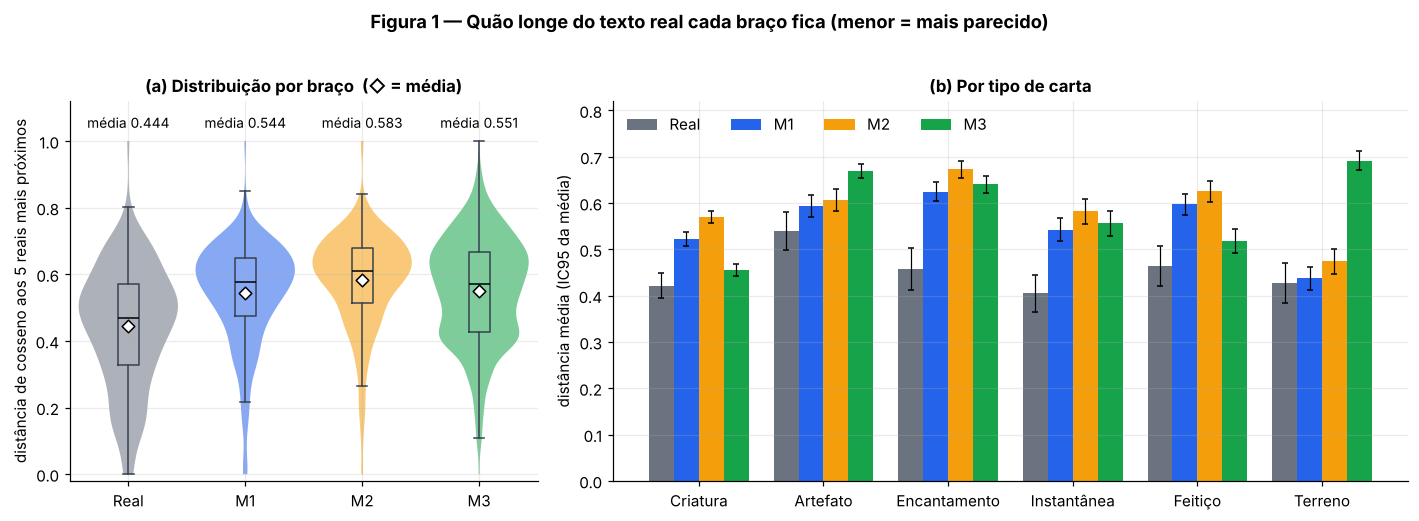

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={'width_ratios': [1, 1.7]})

# (a) distribuição geral
dados = [todos[todos.braco == b].d_knn.dropna().values for b in ORDEM]
vp = ax[0].violinplot(dados, showextrema=False, widths=.85)
for corpo, b in zip(vp['bodies'], ORDEM):
    corpo.set_facecolor(CORES[b]); corpo.set_alpha(.55); corpo.set_edgecolor('none')
ax[0].boxplot(dados, widths=.18, showfliers=False, medianprops=dict(color='black'),
              boxprops=dict(color='#374151'), whiskerprops=dict(color='#374151'), capprops=dict(color='#374151'))
for i, d in enumerate(dados, 1):
    ax[0].scatter(i, d.mean(), marker='D', color='white', edgecolor='black', zorder=5, s=34)
    ax[0].text(i, 1.04, f'média {d.mean():.3f}', ha='center', fontsize=9)
ax[0].set_ylim(-.02, 1.12)
ax[0].set_xticks(range(1, 5)); ax[0].set_xticklabels(ORDEM)
ax[0].set_ylabel(f'distância de cosseno aos {K} reais mais próximos')
ax[0].set_title('(a) Distribuição por braço  (◇ = média)')

# (b) por tipo
larg = .2
for j, b in enumerate(ORDEM):
    sub = todos[todos.braco == b]
    med = [sub[sub.tipo == t].d_knn.mean() for t in TIPOS]
    err = [1.96 * sub[sub.tipo == t].d_knn.std() / math.sqrt((sub.tipo == t).sum()) for t in TIPOS]
    ax[1].bar(np.arange(len(TIPOS)) + (j - 1.5) * larg, med, larg, yerr=err, color=CORES[b], label=b,
              capsize=2, error_kw=dict(lw=.8))
ax[1].set_xticks(range(len(TIPOS))); ax[1].set_xticklabels([TIPOS_PT[t] for t in TIPOS])
ax[1].set_ylabel('distância média (IC95 da média)')
ax[1].set_ylim(0, .82)
ax[1].set_title('(b) Por tipo de carta'); ax[1].legend(ncol=4, loc='upper left')
fig.suptitle('Figura 1 — Quão longe do texto real cada braço fica (menor = mais parecido)', fontweight='bold', y=1.02)
fig.tight_layout(); plt.show()

## Figura 2 — Parágrafos e keywords

Um **parágrafo** é uma habilidade (uma linha do texto de regras), sem contar a linha que lista só keywords. As keywords reais vêm do campo `keywords` do Scryfall; nos braços, do campo `palavras_chave`. As barras mostram a **proporção de cartas** em cada contagem.

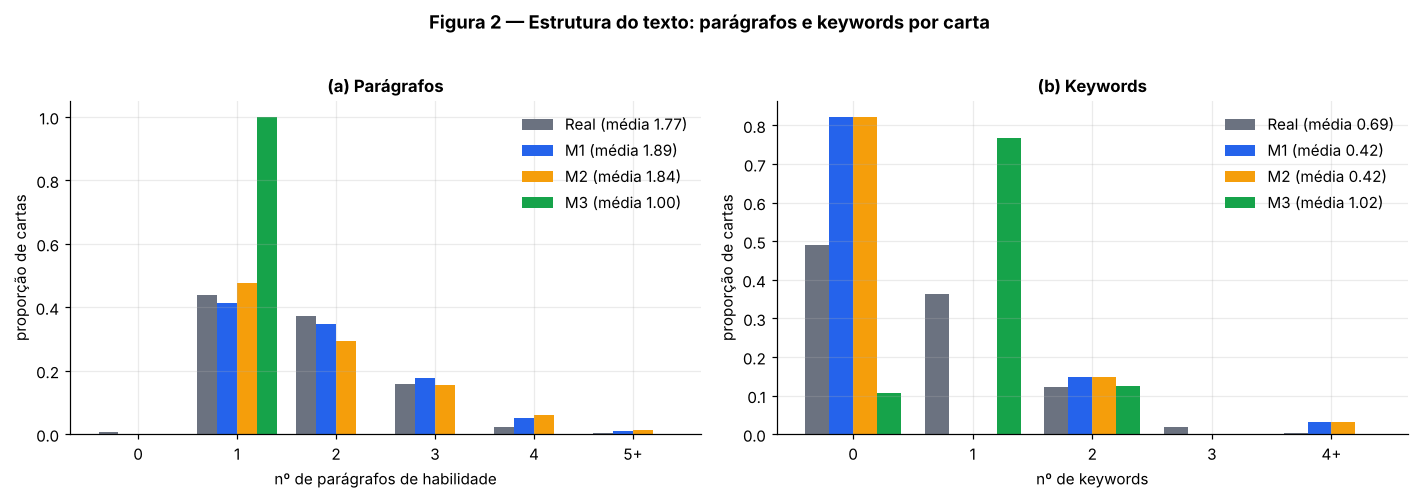

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
def dist_contagem(serie, teto):
    c = serie.clip(upper=teto).value_counts(normalize=True)
    return [c.get(i, 0) for i in range(teto + 1)]

for a, col, teto, rot, tit in [(ax[0], 'n_par', 5, 'nº de parágrafos de habilidade', '(a) Parágrafos'),
                               (ax[1], 'n_kw', 4, 'nº de keywords', '(b) Keywords')]:
    for j, b in enumerate(ORDEM):
        s = todos[todos.braco == b][col]
        p = dist_contagem(s, teto)
        a.bar(np.arange(teto + 1) + (j - 1.5) * .2, p, .2, color=CORES[b], label=f'{b} (média {s.mean():.2f})')
    a.set_xticks(range(teto + 1)); a.set_xticklabels([str(i) for i in range(teto)] + [f'{teto}+'])
    a.set_xlabel(rot); a.set_ylabel('proporção de cartas'); a.set_title(tit); a.legend(loc='upper right')
fig.suptitle('Figura 2 — Estrutura do texto: parágrafos e keywords por carta', fontweight='bold', y=1.02)
fig.tight_layout(); plt.show()

In [7]:
# ---------- (3) criatividade como complexidade textual: combinações raras ----------
def sequencias(pars):
    for p in pars:
        yield ['<s>'] + TOK.findall(p) + ['</s>']

c1, c2, c3, ctx = Counter(), Counter(), Counter(), Counter()
for pars in ref_p.pars_vec:
    for s in sequencias(pars):
        c1.update(s)
        for a, b in zip(s, s[1:]):
            c2[(a, b)] += 1; ctx[a] += 1
        for tri in zip(s, s[1:], s[2:]):
            c3[tri] += 1
N, V, KS = sum(c1.values()), len(c1), 1.0

def surpresa_e_ineditos(pars):
    """Surpresa média por bigrama (bits, suavizada) e fração de trigramas que nunca aparecem no corpus."""
    bits, ined, tot = [], 0, 0
    for s in sequencias(pars):
        for a, b in zip(s, s[1:]):
            pu = (c1[b] + 1) / (N + V + 1)
            bits.append(-math.log2((c2[(a, b)] + KS * pu) / (ctx[a] + KS)))
        for tri in zip(s, s[1:], s[2:]):
            tot += 1; ined += c3[tri] == 0
    return (np.mean(bits) if bits else np.nan, ined / tot if tot else np.nan)

res = [surpresa_e_ineditos(p) for p in todos.pars_vec]
todos['surpresa'] = [r[0] for r in res]
todos['trig_ined'] = [r[1] for r in res]
print('surpresa média (bits/bigrama):', {b: round(float(todos[todos.braco == b].surpresa.mean()), 2) for b in ORDEM})
print('trigramas inéditos:', {b: round(float(todos[todos.braco == b].trig_ined.mean()), 3) for b in ORDEM})

surpresa média (bits/bigrama): {'Real': 4.04, 'M1': 4.63, 'M2': 5.38, 'M3': 4.42}
trigramas inéditos: {'Real': 0.071, 'M1': 0.12, 'M2': 0.224, 'M3': 0.148}


## Figura 3 — "Criatividade" como combinação rara de palavras

Duas medidas contra o corpus de referência: a **surpresa média por bigrama** (quantos bits custa cada par de palavras, dado o corpus; maior = combinações mais raras) e a **fração de trigramas inéditos**. Combinação rara sozinha não prova criatividade, porque texto sem sentido também é raro. Por isso o painel (b) cruza a surpresa com a distância ao real da Figura 1: o ponto ideal para "criativo mas ainda com cara de Magic" fica perto da nuvem **Real**, não no canto de maior surpresa.

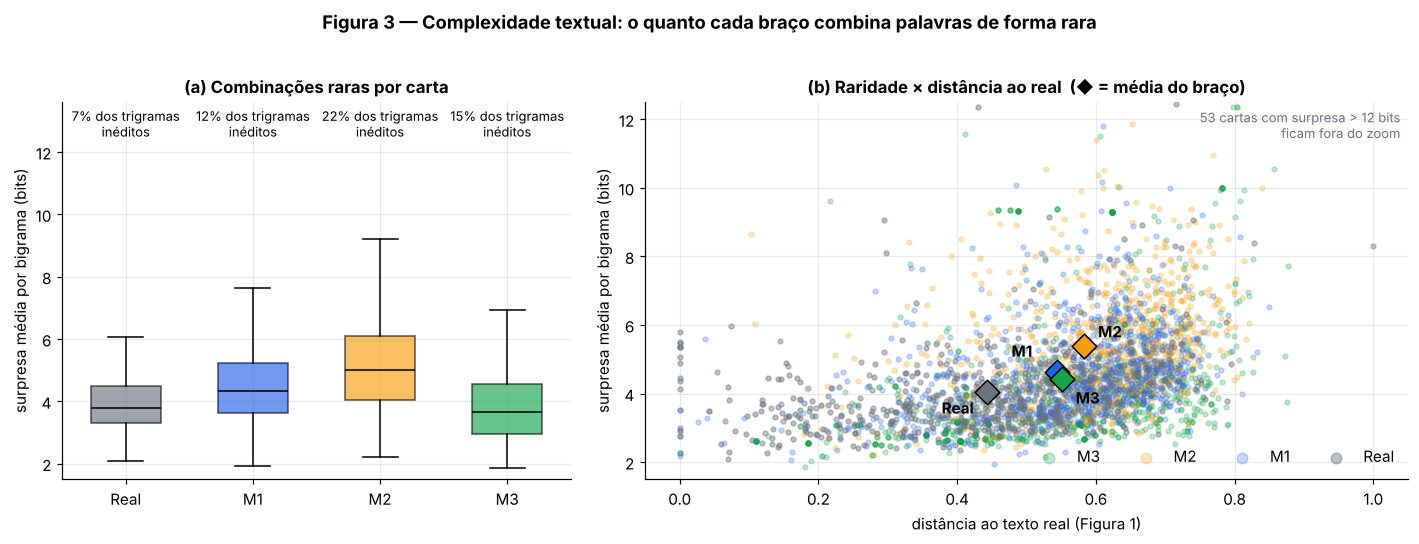

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={'width_ratios': [1, 1.5]})

dados = [todos[todos.braco == b].surpresa.dropna().values for b in ORDEM]
bp = ax[0].boxplot(dados, patch_artist=True, widths=.55, showfliers=False, medianprops=dict(color='black'))
for caixa, b in zip(bp['boxes'], ORDEM):
    caixa.set_facecolor(CORES[b]); caixa.set_alpha(.65)
TETO = 12                                   # poucos textos curtíssimos passam de 12 bits; ficam fora do zoom
ax[0].set_ylim(1.5, TETO + 1.6)
for i, b in enumerate(ORDEM, 1):
    ined = todos[todos.braco == b].trig_ined.mean()
    ax[0].text(i, TETO + .9, f'{ined:.0%} dos trigramas\ninéditos', ha='center', va='center', fontsize=8.5)
ax[0].set_xticks(range(1, 5)); ax[0].set_xticklabels(ORDEM)
ax[0].set_ylabel('surpresa média por bigrama (bits)')
ax[0].set_title('(a) Combinações raras por carta')

for b in ORDEM[::-1]:
    s = todos[todos.braco == b]
    ax[1].scatter(s.d_knn, s.surpresa, s=10, alpha=.25 if b != 'Real' else .45, color=CORES[b], label=b)
for b in ORDEM:
    s = todos[todos.braco == b]
    ax[1].scatter(s.d_knn.mean(), s.surpresa.mean(), s=130, marker='D', color=CORES[b], edgecolor='black', zorder=5)
    desloc = {'Real': (-30, -14), 'M1': (-30, 10), 'M2': (9, 6), 'M3': (9, -16)}[b]
    ax[1].annotate(b, (s.d_knn.mean(), s.surpresa.mean()), xytext=desloc, textcoords='offset points', fontweight='bold')
ax[1].set_ylim(1.5, TETO + .5)
fora = int((todos.surpresa > TETO).sum())
ax[1].text(.99, .98, f'{fora} cartas com surpresa > {TETO} bits\nficam fora do zoom', transform=ax[1].transAxes, ha='right', va='top', fontsize=8.5, color='#6b7280')
ax[1].set_xlabel('distância ao texto real (Figura 1)'); ax[1].set_ylabel('surpresa média por bigrama (bits)')
ax[1].set_title('(b) Raridade × distância ao real  (◆ = média do braço)')
ax[1].legend(markerscale=2.2, loc='lower right', ncol=4)
fig.suptitle('Figura 3 — Complexidade textual: o quanto cada braço combina palavras de forma rara', fontweight='bold', y=1.02)
fig.tight_layout(); plt.show()

## Figura 4 — Regressão de CMC e P/T contra o real

Só as **500 cartas reais** têm gabarito. M1 e M2 usam a mesma regressão, então aparecem juntos (a célula confere que as previsões são idênticas). O M3 é a LLM. A diagonal tracejada é o acerto perfeito; os pontos têm um pequeno ruído horizontal e vertical só para não se empilharem. Para P/T entram as cartas reais com poder e resistência numéricos (criaturas e veículos).

M1 e M2 têm CMC e P/T idênticos nas cartas reais: True


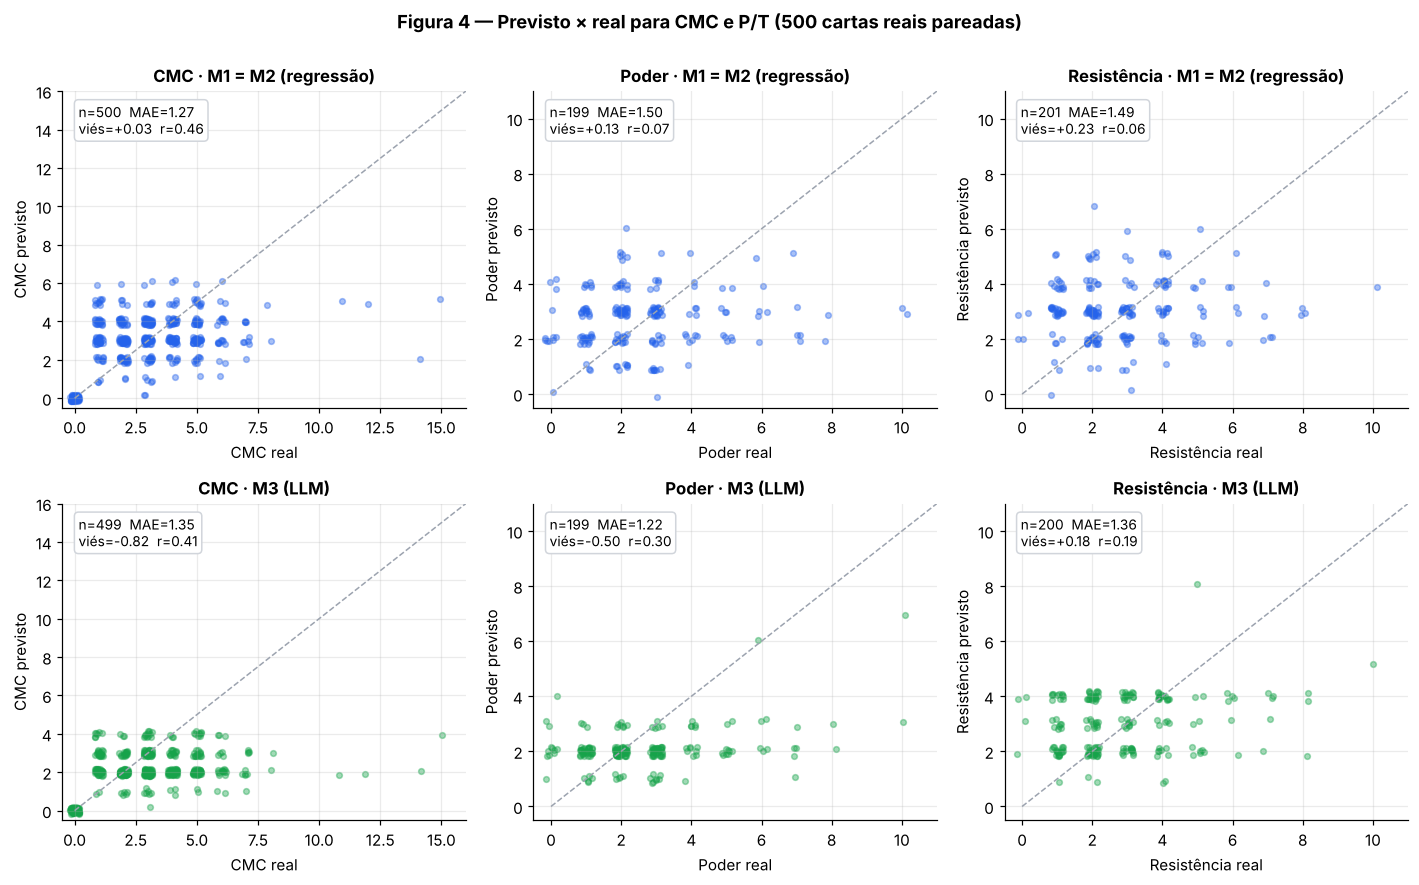

In [9]:
reais = gerado[gerado.origem == 'real']
m1, m2, m3 = (reais[reais.braco == b].set_index('carta_id') for b in ['M1', 'M2', 'M3'])
iguais = all(np.allclose(m1[c], m2.loc[m1.index, c], equal_nan=True) for c in ['cmc', 'poder', 'resist'])
print('M1 e M2 têm CMC e P/T idênticos nas cartas reais:', iguais)

def metricas(df, pred, real_):
    d = df[[pred, real_]].dropna()
    e = d[pred] - d[real_]
    return dict(n=len(d), mae=e.abs().mean(), vies=e.mean(), r=np.corrcoef(d[pred], d[real_])[0, 1])

ALVOS = [('CMC', 'cmc', 'g_cmc'), ('Poder', 'poder', 'g_p'), ('Resistência', 'resist', 'g_t')]
LINHAS4 = [('M1 = M2 (regressão)', m1.reset_index(), '#2563eb'), ('M3 (LLM)', m3.reset_index(), '#16a34a')]

fig, ax = plt.subplots(2, 3, figsize=(13, 8), sharex='col', sharey='col')
for a_ in ax.ravel(): a_.tick_params(labelbottom=True, labelleft=True)
for i, (rot, df, cor) in enumerate(LINHAS4):
    for j, (nome, pred, gab) in enumerate(ALVOS):
        a = ax[i, j]
        d = df[[pred, gab]].dropna()
        lim = max(d.max()) + 1
        a.plot([0, lim], [0, lim], '--', color='#9ca3af', lw=1)
        a.scatter(d[gab] + rng.uniform(-.18, .18, len(d)), d[pred] + rng.uniform(-.18, .18, len(d)),
                  s=14, alpha=.4, color=cor)
        m = metricas(df, pred, gab)
        a.text(.04, .96, f"n={m['n']}  MAE={m['mae']:.2f}\nviés={m['vies']:+.2f}  r={m['r']:.2f}",
               transform=a.transAxes, va='top', fontsize=9, bbox=dict(fc='white', ec='#d1d5db', boxstyle='round'))
        a.set_xlim(-.5, lim); a.set_ylim(-.5, lim)
        a.set_xlabel(f'{nome} real'); a.set_ylabel(f'{nome} previsto')
        a.set_title(f'{nome} · {rot}')
fig.suptitle('Figura 4 — Previsto × real para CMC e P/T (500 cartas reais pareadas)', fontweight='bold', y=1.0)
fig.tight_layout(); plt.show()

## Tabela comparativa

Média por carta com **IC95 por bootstrap** (2.000 reamostragens, semente fixa). A coluna **Real** é a referência (500 cartas do holdout, medidas com a mesma régua). A última coluna aponta o braço com **menor desvio do Real** na estimativa pontual (nas linhas de regressão, o menor erro). Isso mede *semelhança*, não qualidade, e **vale olhar os intervalos**: quando eles se sobrepõem, a diferença não é firme. M1 e M2 só diferem no texto, então nas linhas estruturais eles coincidem por construção.

In [10]:
def boot(v, B=2000):
    v = np.asarray(v, float); v = v[~np.isnan(v)]
    if len(v) == 0:
        return np.nan, np.nan, np.nan
    idx = rng.integers(0, len(v), (B, len(v)))
    m = v[idx].mean(axis=1)
    return v.mean(), *np.percentile(m, [2.5, 97.5])

def fmt(v, casas=3, pct=False):
    m, lo, hi = boot(v)
    if np.isnan(m): return '—'
    if pct: return f'{m:.1%} [{lo:.1%}; {hi:.1%}]'
    return f'{m:.{casas}f} [{lo:.{casas}f}; {hi:.{casas}f}]'

def medias(col, f=lambda s: s):
    return {b: todos[todos.braco == b][col].dropna() for b in ORDEM}

tab, proximo = [], {}
def add(secao, nome, serie_por_braco, casas=3, pct=False):
    linha = {'Seção': secao, 'Métrica': nome}
    for b in ORDEM:
        linha[b] = fmt(serie_por_braco[b], casas, pct) if serie_por_braco.get(b) is not None else '—'
    ref_m = np.nanmean(serie_por_braco['Real'])
    dif = {b: abs(np.nanmean(serie_por_braco[b]) - ref_m) for b in ['M1', 'M2', 'M3']}
    menor = min(dif.values())
    vencedores = [b for b, d in dif.items() if d <= menor + 1e-9]
    linha['Menor desvio do Real'] = '/'.join(vencedores) if len(vencedores) < 3 else 'empate'
    tab.append(linha)

add('Texto', 'Distância aos 5 reais mais próximos', medias('d_knn'))
add('Estrutura', 'Parágrafos por carta', medias('n_par'), 2)
add('Estrutura', 'Palavras por carta', medias('n_pal'), 1)
add('Estrutura', 'Keywords por carta', medias('n_kw'), 2)
add('Estrutura', 'Cartas com ≥ 1 keyword', {b: (todos[todos.braco == b].n_kw >= 1).astype(float) for b in ORDEM}, pct=True)
add('Criatividade', 'Surpresa por bigrama (bits)', medias('surpresa'), 2)
add('Criatividade', 'Trigramas inéditos no corpus', medias('trig_ined'), pct=True)
tabela = pd.DataFrame(tab)

# regressão: erro absoluto nas cartas reais pareadas (Real = erro zero por definição, vira "—")
def erro_abs(df, pred, gab):
    return (df[pred] - df[gab]).abs().dropna()
reg = []
for rot, pred, gab in [('CMC — erro absoluto médio', 'cmc', 'g_cmc'), ('Poder — erro absoluto médio', 'poder', 'g_p'),
                       ('Resistência — erro absoluto médio', 'resist', 'g_t')]:
    linha = {'Seção': 'Regressão (reais pareadas)', 'Métrica': rot, 'Real': '— (gabarito)'}
    erros = {}
    for b, df in [('M1', m1), ('M2', m2), ('M3', m3)]:
        erros[b] = erro_abs(df, pred, gab)
        linha[b] = fmt(erros[b], 2) + f'  (n={len(erros[b])})'
    mm = {b: e.mean() for b, e in erros.items()}
    menor = min(mm.values())
    v = [b for b, x in mm.items() if x <= menor + 1e-9]
    linha['Menor desvio do Real'] = '/'.join(v) if len(v) < 3 else 'empate'
    reg.append(linha)
tabela = pd.concat([tabela, pd.DataFrame(reg)], ignore_index=True)

# baseline trivial: prever a mediana do tipo no corpus de referência
med_tipo = ref.groupby('tipo')[['cmc']].median().cmc
r_ = real_df.set_index('carta_id')
base_cmc = (r_.cmc - r_.tipo.map(med_tipo)).abs().mean()
med_p = ref.assign(p=num(ref.power), t=num(ref.toughness)).groupby('tipo')[['p', 't']].median()
base_p = (r_.poder - r_.tipo.map(med_p.p)).abs().dropna().mean()
base_t = (r_.resist - r_.tipo.map(med_p.t)).abs().dropna().mean()
display(tabela.style.hide(axis='index').set_properties(**{'text-align': 'left'}))
print(f'Referência trivial (prever a mediana do tipo no corpus): MAE CMC = {base_cmc:.2f} | Poder = {base_p:.2f} | Resistência = {base_t:.2f}')
print('Cartas válidas por braço:', gerado.groupby("braco").size().to_dict(), '| falhas de geração:', falhas)

Referência trivial (prever a mediana do tipo no corpus): MAE CMC = 1.10 | Poder = 1.21 | Resistência = 1.30
Cartas válidas por braço: {'M1': 1000, 'M2': 1000, 'M3': 998} | falhas de geração: {'M1': 0, 'M2': 0, 'M3': 2}


Seção,Métrica,Real,M1,M2,M3,Menor desvio do Real
Texto,Distância aos 5 reais mais próximos,0.444 [0.427; 0.458],0.544 [0.535; 0.554],0.583 [0.574; 0.592],0.551 [0.542; 0.561],M1
Estrutura,Parágrafos por carta,1.77 [1.69; 1.85],1.89 [1.83; 1.95],1.84 [1.78; 1.90],1.00 [1.00; 1.00],M2
Estrutura,Palavras por carta,22.5 [21.4; 23.8],19.1 [18.4; 19.9],20.7 [19.9; 21.5],14.3 [13.8; 14.7],M2
Estrutura,Keywords por carta,0.69 [0.62; 0.75],0.42 [0.36; 0.48],0.42 [0.36; 0.48],1.02 [0.99; 1.05],M1/M2
Estrutura,Cartas com ≥ 1 keyword,51.0% [46.6%; 55.4%],17.8% [15.5%; 20.2%],17.8% [15.4%; 20.2%],89.3% [87.3%; 91.2%],M1/M2
Criatividade,Surpresa por bigrama (bits),4.04 [3.93; 4.15],4.63 [4.53; 4.73],5.38 [5.23; 5.53],4.42 [4.27; 4.59],M3
Criatividade,Trigramas inéditos no corpus,7.1% [6.1%; 8.2%],12.0% [11.1%; 12.9%],22.4% [21.2%; 23.6%],14.8% [13.4%; 16.2%],M1
Regressão (reais pareadas),CMC — erro absoluto médio,— (gabarito),1.27 [1.15; 1.39] (n=500),1.27 [1.16; 1.40] (n=500),1.35 [1.22; 1.49] (n=499),M1/M2
Regressão (reais pareadas),Poder — erro absoluto médio,— (gabarito),1.50 [1.33; 1.70] (n=199),1.50 [1.32; 1.68] (n=199),1.22 [1.05; 1.40] (n=199),M3
Regressão (reais pareadas),Resistência — erro absoluto médio,— (gabarito),1.49 [1.31; 1.67] (n=201),1.49 [1.32; 1.67] (n=201),1.36 [1.20; 1.53] (n=200),M3


## Leitura dos resultados

**Figura 1 (distância ao texto real).** Uma carta real inédita fica a ~0,44 do corpus; é o piso realista. M1 (0,544) e M3 (0,551) têm intervalos que se tocam, então praticamente empatam. O **M2 é o mais distante (0,583)**: o refinamento da LLM afasta o texto do vocabulário do corpus. Por tipo, o M3 fica perto do real nas criaturas, mas é o pior em terrenos (~0,69). O texto do M3 para terreno é muito repetitivo e parte dele usa a redação antiga de mana (`Add {U} to your mana pool`), o que é uma hipótese plausível para o afastamento, não algo testado aqui.

**Figura 2 (parágrafos e keywords).** M1 e M2 reproduzem bem o número de parágrafos (1,89 e 1,84 contra 1,77 do real). O M3 devolve **sempre 1 parágrafo**. Nas keywords, o M1/M2 só produzem 0, 2 ou 4 por construção (o fator 2,0 do `FATOR_KEYWORDS` dobra a contagem real), e só 17,8% das cartas têm alguma, contra 51% no real. O M3 vai para o outro extremo: 89% das cartas têm keyword, e `delve` sozinha aparece 219 vezes.

**Figura 3 (criatividade).** Pela surpresa de bigramas, a ordem do mais comum ao mais raro é Real (4,04), M3 (4,42), M1 (4,63) e M2 (5,38 bits; 22% dos trigramas inéditos, contra 7% no real). Raro não significa bom: no painel (b) o M2 se afasta do real *e* sobe em raridade, o que é compatível com paráfrase estranha tanto quanto com criatividade. Para afirmar criatividade falta avaliação humana (a escala de 1 a 5 do README).

**Figura 4 (regressão).** O CMC previsto tem MAE 1,27 (r = 0,46) no M1/M2 e 1,35 no M3 (viés de −0,82: o M3 subestima o custo). O dado mais importante é a linha de referência: **prever a mediana do tipo dá MAE 1,10 no CMC, 1,21 no poder e 1,30 na resistência**, melhor ou igual aos três braços. Em P/T a regressão não acompanha o real (r ≈ 0,07 e 0,06) e o M3 só chega perto da referência trivial. A diferença M3 × M1 em P/T já aparece como significativa no `relatorio_metricas.md` (Δ = −0,417; IC95 −0,693 a −0,146), enquanto no CMC os intervalos se sobrepõem.

**Limites.** (i) A distância usa TF-IDF, que mede vocabulário compartilhado e não sentido; um embedding de frases seria o próximo passo. (ii) O M1/M2 usam as previsões gravadas nos `.jsonl`; a regressão não foi retreinada aqui. (iii) A referência "Real" é de 500 cartas, então os intervalos dela são mais largos que os dos braços.